# 06 — Comparación de modelos y contexto temporal

Objetivos:
- Revisar el desempeño del baseline por período.
- Comparar regresión logística y LightGBM.
- Evaluar el aporte del año académico como predictor.

Se reutilizan las particiones guardadas del notebook 05.
Se conserva la imputación dentro de cada entrenamiento.

Esta comparación utiliza validación por estudiante.
Todavía no representa una evaluación hacia años futuros.

In [65]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
)
from lightgbm import LGBMClassifier

PROJ_ROOT = Path.cwd()

if PROJ_ROOT.name == "notebooks":
    PROJ_ROOT = PROJ_ROOT.parent

assert (PROJ_ROOT / "src").is_dir()

os.chdir(PROJ_ROOT)

if str(PROJ_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT))

from src.data.load_data import load_processed, load_raw
from src.features.build_features import FEATURES_COLS

with open("configs/config.yaml", encoding="utf-8") as archivo:
    config = yaml.safe_load(archivo)

SEED = int(config["random_seed"])
UMBRAL = 0.50
CLAVES = ["id_alumno", "anio_academico"]

print("Proyecto:", PROJ_ROOT)

Proyecto: /Users/alejo/Desktop/alerta-temprana-desercion


In [66]:
df = (
    load_processed()
    .sort_values(CLAVES)
    .reset_index(drop=True)
)

referencia = pd.read_csv(
    "reports/predicciones_baseline_oof.csv"
).rename(columns={
    "abandono_real": "target_base",
    "probabilidad_abandono": "prob_base",
})

assert not df.duplicated(CLAVES).any()
assert not referencia.duplicated(CLAVES).any()
assert len(df) == len(referencia)

df = df.merge(
    referencia[CLAVES + ["fold", "target_base", "prob_base"]],
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
)

assert df[["fold", "target_base", "prob_base"]].notna().all().all()
assert df["abandono"].astype(int).eq(df["target_base"]).all()

df["fold"] = df["fold"].astype(int)

assert df.groupby("id_alumno")["fold"].nunique().eq(1).all()

# Recuperar la marca de edades originalmente inválidas.
edades = load_raw()[CLAVES + ["edad"]].rename(
    columns={"edad": "edad_original"}
)

df = df.merge(
    edades,
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
)

assert df["edad_original"].notna().all()

df["edad"] = df["edad"].astype(float)
df.loc[df["edad_original"].eq(0), "edad"] = np.nan

print("Registros:", len(df))
print("Estudiantes:", df["id_alumno"].nunique())
print("Edades pendientes de imputación:", df["edad"].isna().sum())

Registros: 1979
Estudiantes: 1019
Edades pendientes de imputación: 3


In [67]:
def calcular_metricas(grupo):
    y_real = grupo["abandono_real"].astype(int)
    probabilidades = grupo["probabilidad_abandono"]
    predicciones = probabilidades.ge(UMBRAL).astype(int)

    positivos = int(y_real.sum())

    return {
        "registros": len(grupo),
        "estudiantes": grupo["id_alumno"].nunique(),
        "positivos": positivos,
        "proporcion_positivos": y_real.mean(),
        "roc_auc": (
            roc_auc_score(y_real, probabilidades)
            if y_real.nunique() == 2 else np.nan
        ),
        "average_precision": (
            average_precision_score(y_real, probabilidades)
            if positivos > 0 else np.nan
        ),
        "precision": precision_score(
            y_real, predicciones, zero_division=0
        ),
        "recall": (
            recall_score(y_real, predicciones, zero_division=0)
            if positivos > 0 else np.nan
        ),
        "alertas": int(predicciones.sum()),
        "falsos_negativos": int(
            (y_real.eq(1) & predicciones.eq(0)).sum()
        ),
    }


def evaluar_por_periodo(predicciones):
    datos = predicciones.copy()

    datos["periodo"] = pd.cut(
        datos["anio_academico"],
        bins=[-np.inf, 2002, 2006, 2017, np.inf],
        labels=[
            "2000-2002",
            "2003-2006",
            "2007-2017",
            "2018-2023",
        ],
    )

    filas = []

    for (modelo, periodo), grupo in datos.groupby(
        ["modelo", "periodo"],
        observed=True,
    ):
        filas.append({
            "modelo": modelo,
            "periodo": str(periodo),
            **calcular_metricas(grupo),
        })

    return pd.DataFrame(filas)

In [68]:
pred_base = df[CLAVES + ["fold"]].copy()

pred_base["modelo"] = "logistica_base"
pred_base["abandono_real"] = df["abandono"].astype(int)
pred_base["probabilidad_abandono"] = df["prob_base"]

diagnostico_base = evaluar_por_periodo(pred_base)

display(diagnostico_base.round(4))

,modelo,periodo,registros,estudiantes,positivos,proporcion_positivos,roc_auc,average_precision,precision,recall,alertas,falsos_negativos
0,logistica_base,2000-2002,14,7,2,0.1429,0.4583,0.2436,0.0000,0.0000,1,2
1,logistica_base,2003-2006,87,47,38,0.4368,0.6241,0.6013,0.5200,0.3421,25,25
2,logistica_base,2007-2017,291,116,75,0.2577,0.6646,0.4358,0.4189,0.4133,74,44
3,logistica_base,2018-2023,1587,925,484,0.3050,0.8603,0.7471,0.7320,0.6095,403,189


In [69]:
X_base = df[FEATURES_COLS].copy()

X_anio = df[
    FEATURES_COLS + ["anio_academico"]
].copy()

y = df["abandono"].astype(int)
groups = df["id_alumno"]

folds = []

for fold in sorted(df["fold"].unique()):
    idx_train = np.flatnonzero(df["fold"].ne(fold).to_numpy())
    idx_valid = np.flatnonzero(df["fold"].eq(fold).to_numpy())

    assert set(groups.iloc[idx_train]).isdisjoint(
        set(groups.iloc[idx_valid])
    )

    assert y.iloc[idx_train].nunique() == 2
    assert y.iloc[idx_valid].nunique() == 2

    folds.append((int(fold), idx_train, idx_valid))

assert len(folds) == int(config["split"]["n_splits"])

print("Predictores originales:", X_base.shape[1])
print("Predictores incluyendo año:", X_anio.shape[1])
print("Folds recuperados:", len(folds))

Predictores originales: 13
Predictores incluyendo año: 14
Folds recuperados: 5


In [70]:
logistica_anio = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        class_weight=None,
    )),
])

lightgbm_inicial = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("modelo", LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=7,
        max_depth=3,
        min_child_samples=30,
        reg_lambda=1.0,
        class_weight=None,
        random_state=SEED,
        n_jobs=2,
        verbosity=-1,
    )),
])

experimentos = {
    "logistica_anio": (logistica_anio, X_anio),
    "lightgbm_base": (lightgbm_inicial, X_base),
    "lightgbm_anio": (clone(lightgbm_inicial), X_anio),
}

print("Escenarios nuevos:", list(experimentos))

Escenarios nuevos: ['logistica_anio', 'lightgbm_base', 'lightgbm_anio']


In [71]:
bloques_predicciones = [pred_base]

for nombre, (pipeline, X_actual) in experimentos.items():
    probabilidades_oof = np.full(len(df), np.nan)
    veces_evaluado = np.zeros(len(df), dtype=int)

    for fold, idx_train, idx_valid in folds:
        modelo_fold = clone(pipeline)

        modelo_fold.fit(
            X_actual.iloc[idx_train],
            y.iloc[idx_train],
        )

        probabilidades_oof[idx_valid] = (
            modelo_fold.predict_proba(
                X_actual.iloc[idx_valid]
            )[:, 1]
        )

        veces_evaluado[idx_valid] += 1

        print(f"{nombre} — fold {fold} terminado")

    assert np.isfinite(probabilidades_oof).all()
    assert (veces_evaluado == 1).all()

    salida = df[CLAVES + ["fold"]].copy()
    salida["modelo"] = nombre
    salida["abandono_real"] = y.to_numpy()
    salida["probabilidad_abandono"] = probabilidades_oof

    bloques_predicciones.append(salida)

predicciones_comparacion = pd.concat(
    bloques_predicciones,
    ignore_index=True,
)

assert not predicciones_comparacion.duplicated(
    ["modelo"] + CLAVES
).any()

print("Predicciones por escenario:")
display(predicciones_comparacion.groupby("modelo").size())

logistica_anio — fold 1 terminado
logistica_anio — fold 2 terminado
logistica_anio — fold 3 terminado
logistica_anio — fold 4 terminado
logistica_anio — fold 5 terminado
lightgbm_base — fold 1 terminado
lightgbm_base — fold 2 terminado
lightgbm_base — fold 3 terminado
lightgbm_base — fold 4 terminado
lightgbm_base — fold 5 terminado
lightgbm_anio — fold 1 terminado
lightgbm_anio — fold 2 terminado
lightgbm_anio — fold 3 terminado
lightgbm_anio — fold 4 terminado
lightgbm_anio — fold 5 terminado
Predicciones por escenario:


modelo
lightgbm_anio     1979
lightgbm_base     1979
logistica_anio    1979
logistica_base    1979
dtype: int64

In [72]:
filas = []

for (modelo, fold), grupo in predicciones_comparacion.groupby(
    ["modelo", "fold"]
):
    filas.append({
        "modelo": modelo,
        "fold": fold,
        **calcular_metricas(grupo),
    })

metricas_comparacion = pd.DataFrame(filas)

columnas_metricas = [
    "roc_auc",
    "average_precision",
    "precision",
    "recall",
]

resumen_comparacion = (
    metricas_comparacion
    .groupby("modelo")[columnas_metricas]
    .agg(["mean", "std"])
)

display(resumen_comparacion.round(4))

roc_auc         average_precision         precision          \
                  mean     std              mean     std      mean     std   
modelo                                                                       
lightgbm_anio   0.8473  0.0166            0.7301  0.0272    0.7165  0.0653   
lightgbm_base   0.8378  0.0152            0.7198  0.0225    0.7105  0.0534   
logistica_anio  0.8276  0.0166            0.7058  0.0294    0.6736  0.0211   
logistica_base  0.8281  0.0162            0.7063  0.0290    0.6742  0.0221   

                recall          
                  mean     std  
modelo                          
lightgbm_anio   0.5470  0.0368  
lightgbm_base   0.5377  0.0179  
logistica_anio  0.5637  0.0253  
logistica_base  0.5653  0.0239

In [73]:
metricas_periodos = evaluar_por_periodo(
    predicciones_comparacion
)

display(
    metricas_periodos.sort_values(
        ["periodo", "modelo"]
    ).round(4)
)

print("Detalle de 2003–2006:")

display(
    metricas_periodos.loc[
        metricas_periodos["periodo"].eq("2003-2006")
    ].round(4)
)

,modelo,periodo,registros,estudiantes,positivos,proporcion_positivos,roc_auc,average_precision,precision,recall,alertas,falsos_negativos
0,lightgbm_anio,2000-2002,14,7,2,0.1429,0.8333,0.4167,0.0000,0.0000,0,2
4,lightgbm_base,2000-2002,14,7,2,0.1429,0.7083,0.3095,0.0000,0.0000,0,2
8,logistica_anio,2000-2002,14,7,2,0.1429,0.5000,0.3269,0.0000,0.0000,1,2
12,logistica_base,2000-2002,14,7,2,0.1429,0.4583,0.2436,0.0000,0.0000,1,2
1,lightgbm_anio,2003-2006,87,47,38,0.4368,0.7497,0.6684,0.6000,0.5526,35,17
5,lightgbm_base,2003-2006,87,47,38,0.4368,0.6740,0.6325,0.6087,0.3684,23,24
9,logistica_anio,2003-2006,87,47,38,0.4368,0.6257,0.6067,0.5909,0.3421,22,25
13,logistica_base,2003-2006,87,47,38,0.4368,0.6241,0.6013,0.5200,0.3421,25,25
2,lightgbm_anio,2007-2017,291,116,75,0.2577,0.7019,0.4382,0.4615,0.3200,52,51
6,lightgbm_base,2007-2017,291,116,75,0.2577,0.6891,0.4334,0.4828,0.3733,58,47


Detalle de 2003–2006:


,modelo,periodo,registros,estudiantes,positivos,proporcion_positivos,roc_auc,average_precision,precision,recall,alertas,falsos_negativos
1,lightgbm_anio,2003-2006,87,47,38,0.4368,0.7497,0.6684,0.6000,0.5526,35,17
5,lightgbm_base,2003-2006,87,47,38,0.4368,0.6740,0.6325,0.6087,0.3684,23,24
9,logistica_anio,2003-2006,87,47,38,0.4368,0.6257,0.6067,0.5909,0.3421,22,25
13,logistica_base,2003-2006,87,47,38,0.4368,0.6241,0.6013,0.5200,0.3421,25,25


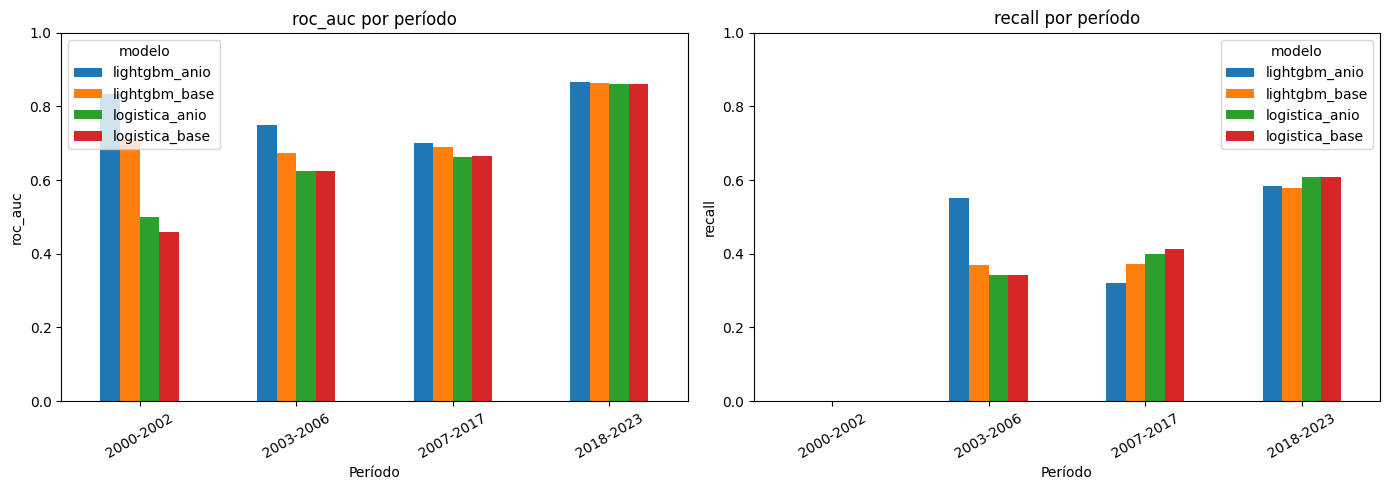

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metrica in zip(axes, ["roc_auc", "recall"]):
    tabla = metricas_periodos.pivot(
        index="periodo",
        columns="modelo",
        values=metrica,
    )

    tabla.plot.bar(ax=ax)

    ax.set_ylim(0, 1)
    ax.set_title(f"{metrica} por período")
    ax.set_xlabel("Período")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [75]:
comparaciones = [
    ("logistica_anio", "logistica_base"),
    ("lightgbm_base", "logistica_base"),
    ("lightgbm_anio", "lightgbm_base"),
]

for metrica in ["roc_auc", "average_precision"]:
    tabla = metricas_comparacion.pivot(
        index="fold",
        columns="modelo",
        values=metrica,
    )

    diferencias = pd.DataFrame(index=tabla.index)

    for candidato, referencia_modelo in comparaciones:
        diferencias[f"{candidato} - {referencia_modelo}"] = (
            tabla[candidato] - tabla[referencia_modelo]
        )

    print(f"\nDiferencias de {metrica}:")
    display(diferencias.round(4))

    print("Diferencia media:")
    display(diferencias.mean().round(4))


Diferencias de roc_auc:


,logistica_anio - logistica_base,lightgbm_base - logistica_base,lightgbm_anio - lightgbm_base
fold,,,
1,-0.0000,-0.0052,0.0076
2,-0.0005,0.0129,0.0066
3,-0.0005,0.0185,0.0098
4,0.0001,0.0192,0.0151
5,-0.0012,0.0034,0.0084


Diferencia media:


logistica_anio - logistica_base   -0.0004
lightgbm_base - logistica_base     0.0098
lightgbm_anio - lightgbm_base      0.0095
dtype: float64


Diferencias de average_precision:


,logistica_anio - logistica_base,lightgbm_base - logistica_base,lightgbm_anio - lightgbm_base
fold,,,
1,-0.0018,0.0290,0.0074
2,0.0014,0.0197,0.0235
3,-0.0016,-0.0103,0.0052
4,0.0009,0.0025,0.0181
5,-0.0015,0.0263,-0.0024


Diferencia media:


logistica_anio - logistica_base   -0.0005
lightgbm_base - logistica_base     0.0135
lightgbm_anio - lightgbm_base      0.0104
dtype: float64

In [76]:
carpeta_reportes = PROJ_ROOT / "reports"
carpeta_reportes.mkdir(parents=True, exist_ok=True)

metricas_comparacion.to_csv(
    carpeta_reportes / "comparacion_modelos_folds.csv",
    index=False,
)

resumen_comparacion.to_csv(
    carpeta_reportes / "resumen_comparacion_modelos.csv",
)

metricas_periodos.to_csv(
    carpeta_reportes / "comparacion_modelos_periodos.csv",
    index=False,
)

predicciones_comparacion.to_csv(
    carpeta_reportes / "predicciones_comparacion_oof.csv",
    index=False,
)

print("Resultados de comparación guardados.")

Resultados de comparación guardados.


## Conclusiones de la comparación

Se compararon cuatro escenarios sobre 1.979 registros de 1.019 estudiantes, usando los mismos cinco folds. La tabla muestra medias entre folds.

| Escenario | ROC-AUC | Average Precision |
|---|---:|---:|
| Logística base | 0,8281 | 0,7063 |
| Logística con año | 0,8276 | 0,7058 |
| LightGBM base | 0,8378 | 0,7198 |
| LightGBM con año | **0,8473** | **0,7301** |

- **Aporte del año:** no mejoró la logística. En LightGBM aumentó el ROC-AUC en los cinco folds y la Average Precision en cuatro de cinco.
- **Alertas:** con corte 0,50, LightGBM con año tuvo mayor precisión media que la logística base (71,65 % frente a 67,42 %), pero menor recall (54,70 % frente a 56,53 %). Ordenar mejor el riesgo no implica detectar más abandonos con ese corte.
- **Período 2003–2006:** frente al baseline, LightGBM con año elevó el ROC-AUC de 0,6241 a 0,7497 y el recall de 34,21 % a 55,26 %. Son solo 87 registros; la mejora no fue uniforme: en 2007–2017 el recall bajó de 41,33 % a 32,00 %.
- **Período 2018–2023:** el ROC-AUC aumentó de 0,8603 a 0,8673, aunque el recall disminuyó de 60,95 % a 58,47 %. Las métricas por período agrupan predicciones fuera de muestra.

**Decisión provisional:** continuar con LightGBM con año y conservar la logística base como referencia. Antes de definir el modelo final faltan evaluación temporal con etiquetas disponibles a dos años, calibración, elección del umbral, explicabilidad e intervalos de confianza por estudiante. GroupKFold no demuestra por sí solo generalización a años futuros.
